<a href="https://colab.research.google.com/github/dan456r-st/study_cnn_mnist_lab1/blob/main/%D0%9B%D0%A0_%D0%BF%D0%BE_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [83]:
import os, random, math, time, itertools
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
from torchvision.utils import make_grid
from torchvision.models import resnet50, ResNet50_Weights
from PIL import Image
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

In [84]:
#Задаём сиды для повторяемости экспериментов
def seed_everything(seed: int = 69):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


seed_everything(69)

In [85]:
device = torch.device("cuda")

In [86]:
root = './data'

In [156]:
# Статистики для нормализации данных
raw = datasets.MNIST(root=root, train=True, download=True)
x = raw.data.float() / 255.0

mnist_mean = (x.mean().item(),)
mnist_std = (x.std().item(),)

print('MNIST mean:', mnist_mean)
print('MNIST std:', mnist_std)

MNIST mean: (0.13066047430038452,)
MNIST std: (0.30810782313346863,)


In [88]:
# Нормализация
train_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mnist_mean, mnist_std),
])

test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mnist_mean, mnist_std),
])

In [89]:
full_train = datasets.MNIST(root=root, train=True, download=True, transform=train_transform)
mnist_test = datasets.MNIST(root=root, train=False, download=True, transform=test_transform)

len(full_train), len(mnist_test)

(60000, 10000)

In [90]:
# Разбиение на выборки
val_ratio = 0.1
val_size = int(len(full_train) * val_ratio)
train_size = len(full_train) - val_size
mnist_train, mnist_val = random_split(full_train, [train_size, val_size])
len(mnist_train), len(mnist_val), len(mnist_test)

(54000, 6000, 10000)

In [132]:
# Модель
class MyCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2), # 28x28 -> 14x14

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2), # 14x14 -> 7x7
            nn.Dropout(0.25),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d((1, 1)), # 7x7 -> 1x1
            nn.Dropout(0.5)
        )
        self.head = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.head(x)
        return x

model_mnist = MyCNN().to(device)

In [133]:
def accuracy(logits, y):
    preds = logits.argmax(dim=1)
    return (preds == y).float().mean().item()

In [134]:
def run_epoch(model, loader, criterion, optimizer=None):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()


    total_loss, total_acc, total_count = 0.0, 0.0, 0


    for x, y in tqdm(loader, leave=False):
        x, y = x.to(device), y.to(device)
        if is_train:
            optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(is_train):
            logits = model(x)
            loss = criterion(logits, y)
            if is_train:
                loss.backward()
                optimizer.step()
        bs = x.size(0)
        total_loss += loss.item() * bs
        total_acc += accuracy(logits, y) * bs
        total_count += bs

    return total_loss/total_count, total_acc/total_count

In [135]:
# Параметры обучения и загрузчики
batch_size = 128

train_loader = DataLoader(mnist_train, batch_size=batch_size, shuffle=True, pin_memory=True)
val_loader = DataLoader(mnist_val, batch_size=batch_size, shuffle=False, pin_memory=True)
test_loader = DataLoader(mnist_test, batch_size=batch_size, shuffle=False, pin_memory=True)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_mnist.parameters(), lr=1e-3)

In [136]:
num_epochs = 20
hist = {'train_loss':[], 'train_acc':[], 'val_loss':[], 'val_acc':[]}

In [137]:
for epoch in range(1, num_epochs+1):
    tr_loss, tr_acc = run_epoch(model_mnist, train_loader, criterion, optimizer)
    va_loss, va_acc = run_epoch(model_mnist, val_loader, criterion, optimizer=None)


    hist['train_loss'].append(tr_loss)
    hist['train_acc'].append(tr_acc)
    hist['val_loss'].append(va_loss)
    hist['val_acc'].append(va_acc)


    print(f"Epoch {epoch:02d} | Train: loss={tr_loss:.4f}, acc={tr_acc:.4f} | Val: loss={va_loss:.4f}, acc={va_acc:.4f}")

  0%|          | 0/422 [00:00<?, ?it/s]

  0%|          | 0/47 [00:00<?, ?it/s]

Epoch 01 | Train: loss=0.7649, acc=0.7357 | Val: loss=0.2176, acc=0.9348


  0%|          | 0/422 [00:00<?, ?it/s]

  0%|          | 0/47 [00:00<?, ?it/s]

Epoch 02 | Train: loss=0.2637, acc=0.9193 | Val: loss=0.1531, acc=0.9525


... (50 outputs left out)

Epoch 19 | Train: loss=0.0542, acc=0.9833 | Val: loss=0.0278, acc=0.9913


  0%|          | 0/422 [00:00<?, ?it/s]

  0%|          | 0/47 [00:00<?, ?it/s]

Epoch 20 | Train: loss=0.0511, acc=0.9847 | Val: loss=0.0269, acc=0.9913


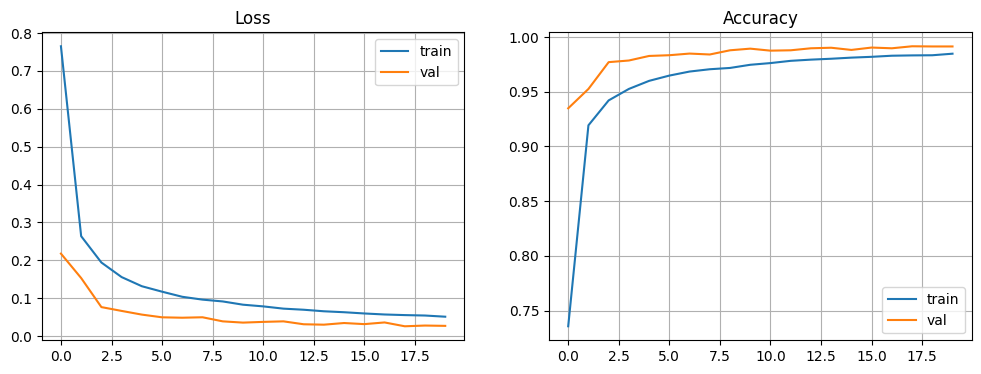

In [143]:
# Графики обучения
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(hist['train_loss'], label='train')
plt.plot(hist['val_loss'], label='val')
plt.title('Loss')
plt.legend()
plt.grid(True)


plt.subplot(1,2,2)
plt.plot(hist['train_acc'], label='train')
plt.plot(hist['val_acc'], label='val')
plt.title('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

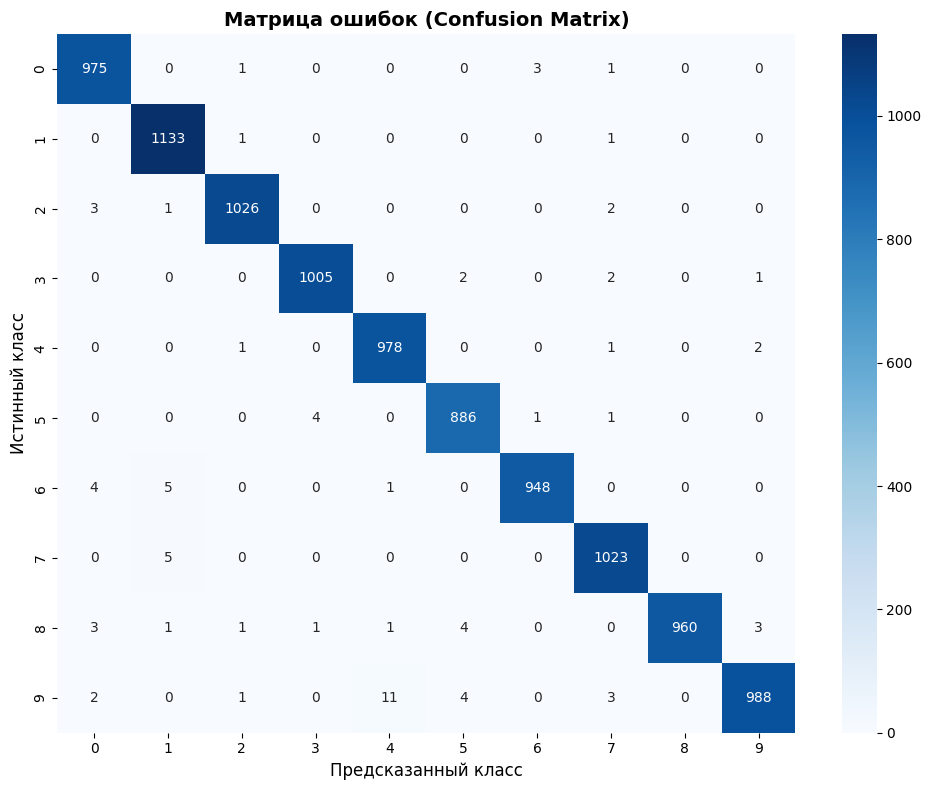

              precision    recall  f1-score   support

           0     0.9878    0.9949    0.9914       980
           1     0.9895    0.9982    0.9939      1135
           2     0.9952    0.9942    0.9947      1032
           3     0.9950    0.9950    0.9950      1010
           4     0.9869    0.9959    0.9914       982
           5     0.9888    0.9933    0.9911       892
           6     0.9958    0.9896    0.9927       958
           7     0.9894    0.9951    0.9922      1028
           8     1.0000    0.9856    0.9928       974
           9     0.9940    0.9792    0.9865      1009

    accuracy                         0.9922     10000
   macro avg     0.9922    0.9921    0.9922     10000
weighted avg     0.9922    0.9922    0.9922     10000



In [154]:
# Оценка результатов
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

def collect_preds(model, loader):
    model.eval()
    y_true, y_pred = [], []
    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(device)
            logits = model(xb)
            preds = logits.argmax(dim=1).cpu()
            y_true.append(yb)
            y_pred.append(preds)
    y_true = torch.cat(y_true).numpy()
    y_pred = torch.cat(y_pred).numpy()
    return y_true, y_pred

def plot_confusion_matrix(model, loader):
    y_true, y_pred = collect_preds(model, loader)
    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=range(10), yticklabels=range(10))
    plt.xlabel('Предсказанный класс', fontsize=12)
    plt.ylabel('Истинный класс', fontsize=12)
    plt.title('Матрица ошибок (Confusion Matrix)', fontsize=14, weight='bold')
    plt.tight_layout()
    plt.show()

    print(classification_report(y_true, y_pred, digits=4))
    return cm

cm = plot_confusion_matrix(model_mnist, test_loader)